In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
import numpy as np
sys.path.append(os.path.dirname(os.getcwd()))

# import Antoine calculator
from src.pure import AntoineCalculator

# instantiate the calculator
antoine_calc = AntoineCalculator()

In [2]:
# define compound
compound = {'CH3':3, 'CH':1, 'CH2COO':1}#{'H2O': 1}
#compound = {'H2O': 1}
#compound = {'DOH': 1}

# instantiate property calculator
from src.pure import PropertyCalculator
pure_calc = PropertyCalculator()

# calculate the required properties
critical_props = pure_calc.calculate(compound, properties=['tc', 'pc', 'tb', 'ac'])

# solve for the Antoine parameters
results = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props, method="acentric_factor")

Characteristic points (T [K], P [bar]): (387.6976301304226, 1.01325), (324.02227358748513, 1.2135205366738329), (462.8889622678359, 31.203983022183035)


In [3]:
# print the anointe parameters
print(f"A: {results['A']}")
print(f"B: {results['B']}")
print(f"C: {results['C']}")
# print the range of T: tb to Tc
print(f"T range: {critical_props['tb']} K to {critical_props['tc']} K")

A: 0.16654969596722502
B: -10.786566604397194
C: -454.76446965171687
T range: 387.6976301304226 K to 462.8889622678359 K


P_sat_calc min: 0.0 bar
P_sat_calc max: 1.4508718496139781e+152 bar
P_sat_calc max should be: 31.203983022183035 bar


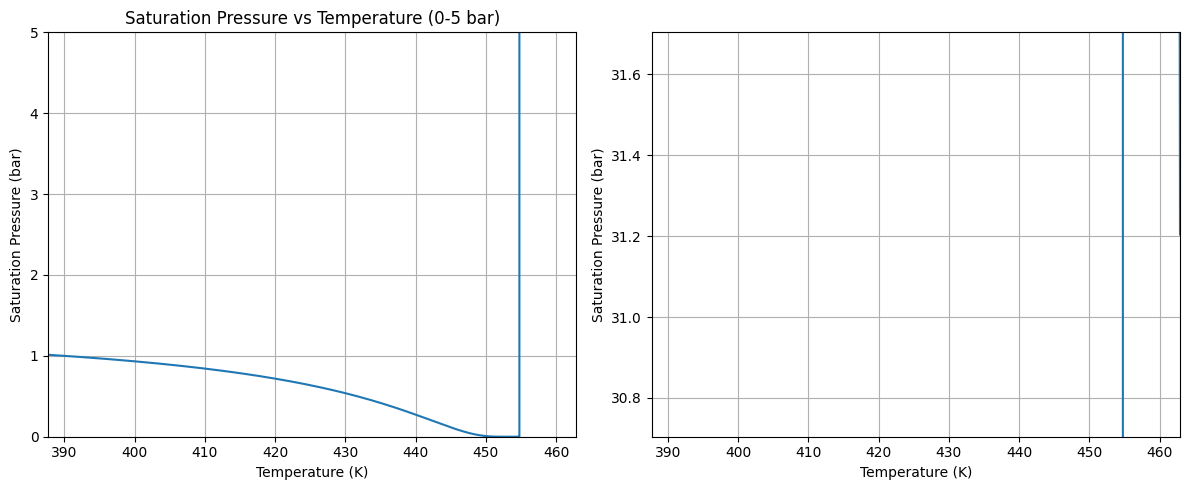

In [4]:
# create T range
T_range = np.linspace(critical_props['tb'], critical_props['tc'], 1000)
# calculate Psat using the calculated Antoine parameters
P_sat_calc = antoine_calc.antoine_correlation(A=results['A'],
                                              B=results['B'],
                                              C=results['C'],
                                              T=T_range)
# print max and min of P_sat_calc
print(f"P_sat_calc min: {min(P_sat_calc)} bar")
print(f"P_sat_calc max: {max(P_sat_calc)} bar")
print(f"P_sat_calc max should be: {critical_props['pc']} bar")

# plot zoomed in version: where psat is minimum and maximum
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: zoomed to 0-5 bar
ax1.plot(T_range, P_sat_calc)
ax1.set_xlim(critical_props['tb'], critical_props['tc'])
ax1.set_ylim(0, 5)
ax1.set_xlabel('Temperature (K)')
ax1.set_ylabel('Saturation Pressure (bar)')
ax1.set_title('Saturation Pressure vs Temperature (0-5 bar)')
ax1.grid()

# Right subplot: zoomed around maximum
psat_max = np.max(P_sat_calc)
ax2.plot(T_range, P_sat_calc)
ax2.set_xlim(critical_props['tb'], critical_props['tc'])
ax2.set_ylim(critical_props['pc'] - 0.5, critical_props['pc'] + 0.5)  # adjust range as needed
ax2.set_xlabel('Temperature (K)')
ax2.set_ylabel('Saturation Pressure (bar)')
#ax2.set_title(f'Saturation Pressure vs Temperature (around max = {psat_max:.2f} bar)')
ax2.grid()

plt.tight_layout()
plt.show()

In [3]:
import numpy as np
n_data = 10
x1_ae = np.linspace(0.00, 1.00, n_data)
x2_ae = np.zeros(n_data)
x3_ae = 1 - x1_ae

# B-E binary edge (A=0): x2 + x3 = 1
x1_be = np.zeros(n_data)
x2_be = np.linspace(0.00, 1.00, n_data)
x3_be = 1 - x2_be

x_all = np.vstack([
    np.column_stack([x1_ae, x2_ae, x3_ae]),  # A-E edge
    np.column_stack([x1_be, x2_be, x3_be])   # B-E edge
])
x_all

array([[0.        , 0.        , 1.        ],
       [0.11111111, 0.        , 0.88888889],
       [0.22222222, 0.        , 0.77777778],
       [0.33333333, 0.        , 0.66666667],
       [0.44444444, 0.        , 0.55555556],
       [0.55555556, 0.        , 0.44444444],
       [0.66666667, 0.        , 0.33333333],
       [0.77777778, 0.        , 0.22222222],
       [0.88888889, 0.        , 0.11111111],
       [1.        , 0.        , 0.        ],
       [0.        , 0.        , 1.        ],
       [0.        , 0.11111111, 0.88888889],
       [0.        , 0.22222222, 0.77777778],
       [0.        , 0.33333333, 0.66666667],
       [0.        , 0.44444444, 0.55555556],
       [0.        , 0.55555556, 0.44444444],
       [0.        , 0.66666667, 0.33333333],
       [0.        , 0.77777778, 0.22222222],
       [0.        , 0.88888889, 0.11111111],
       [0.        , 1.        , 0.        ]])